In [2]:
import kagglehub
path = kagglehub.dataset_download("vaishnavishinde304/skin-disease-dataset")


100%|██████████| 1.38G/1.38G [00:12<00:00, 115MB/s]

Extracting files...


Resolved Test directory path: /root/.cache/kagglehub/datasets/vaishnavishinde304/skin-disease-dataset/versions/1/skin_diseases_split/test
Using device: cuda


preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/3.16k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/225 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/3374 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Test dataset classes: 23
Model classes: 23

Number of test images: 3374
Measured test accuracy: 72.1103%


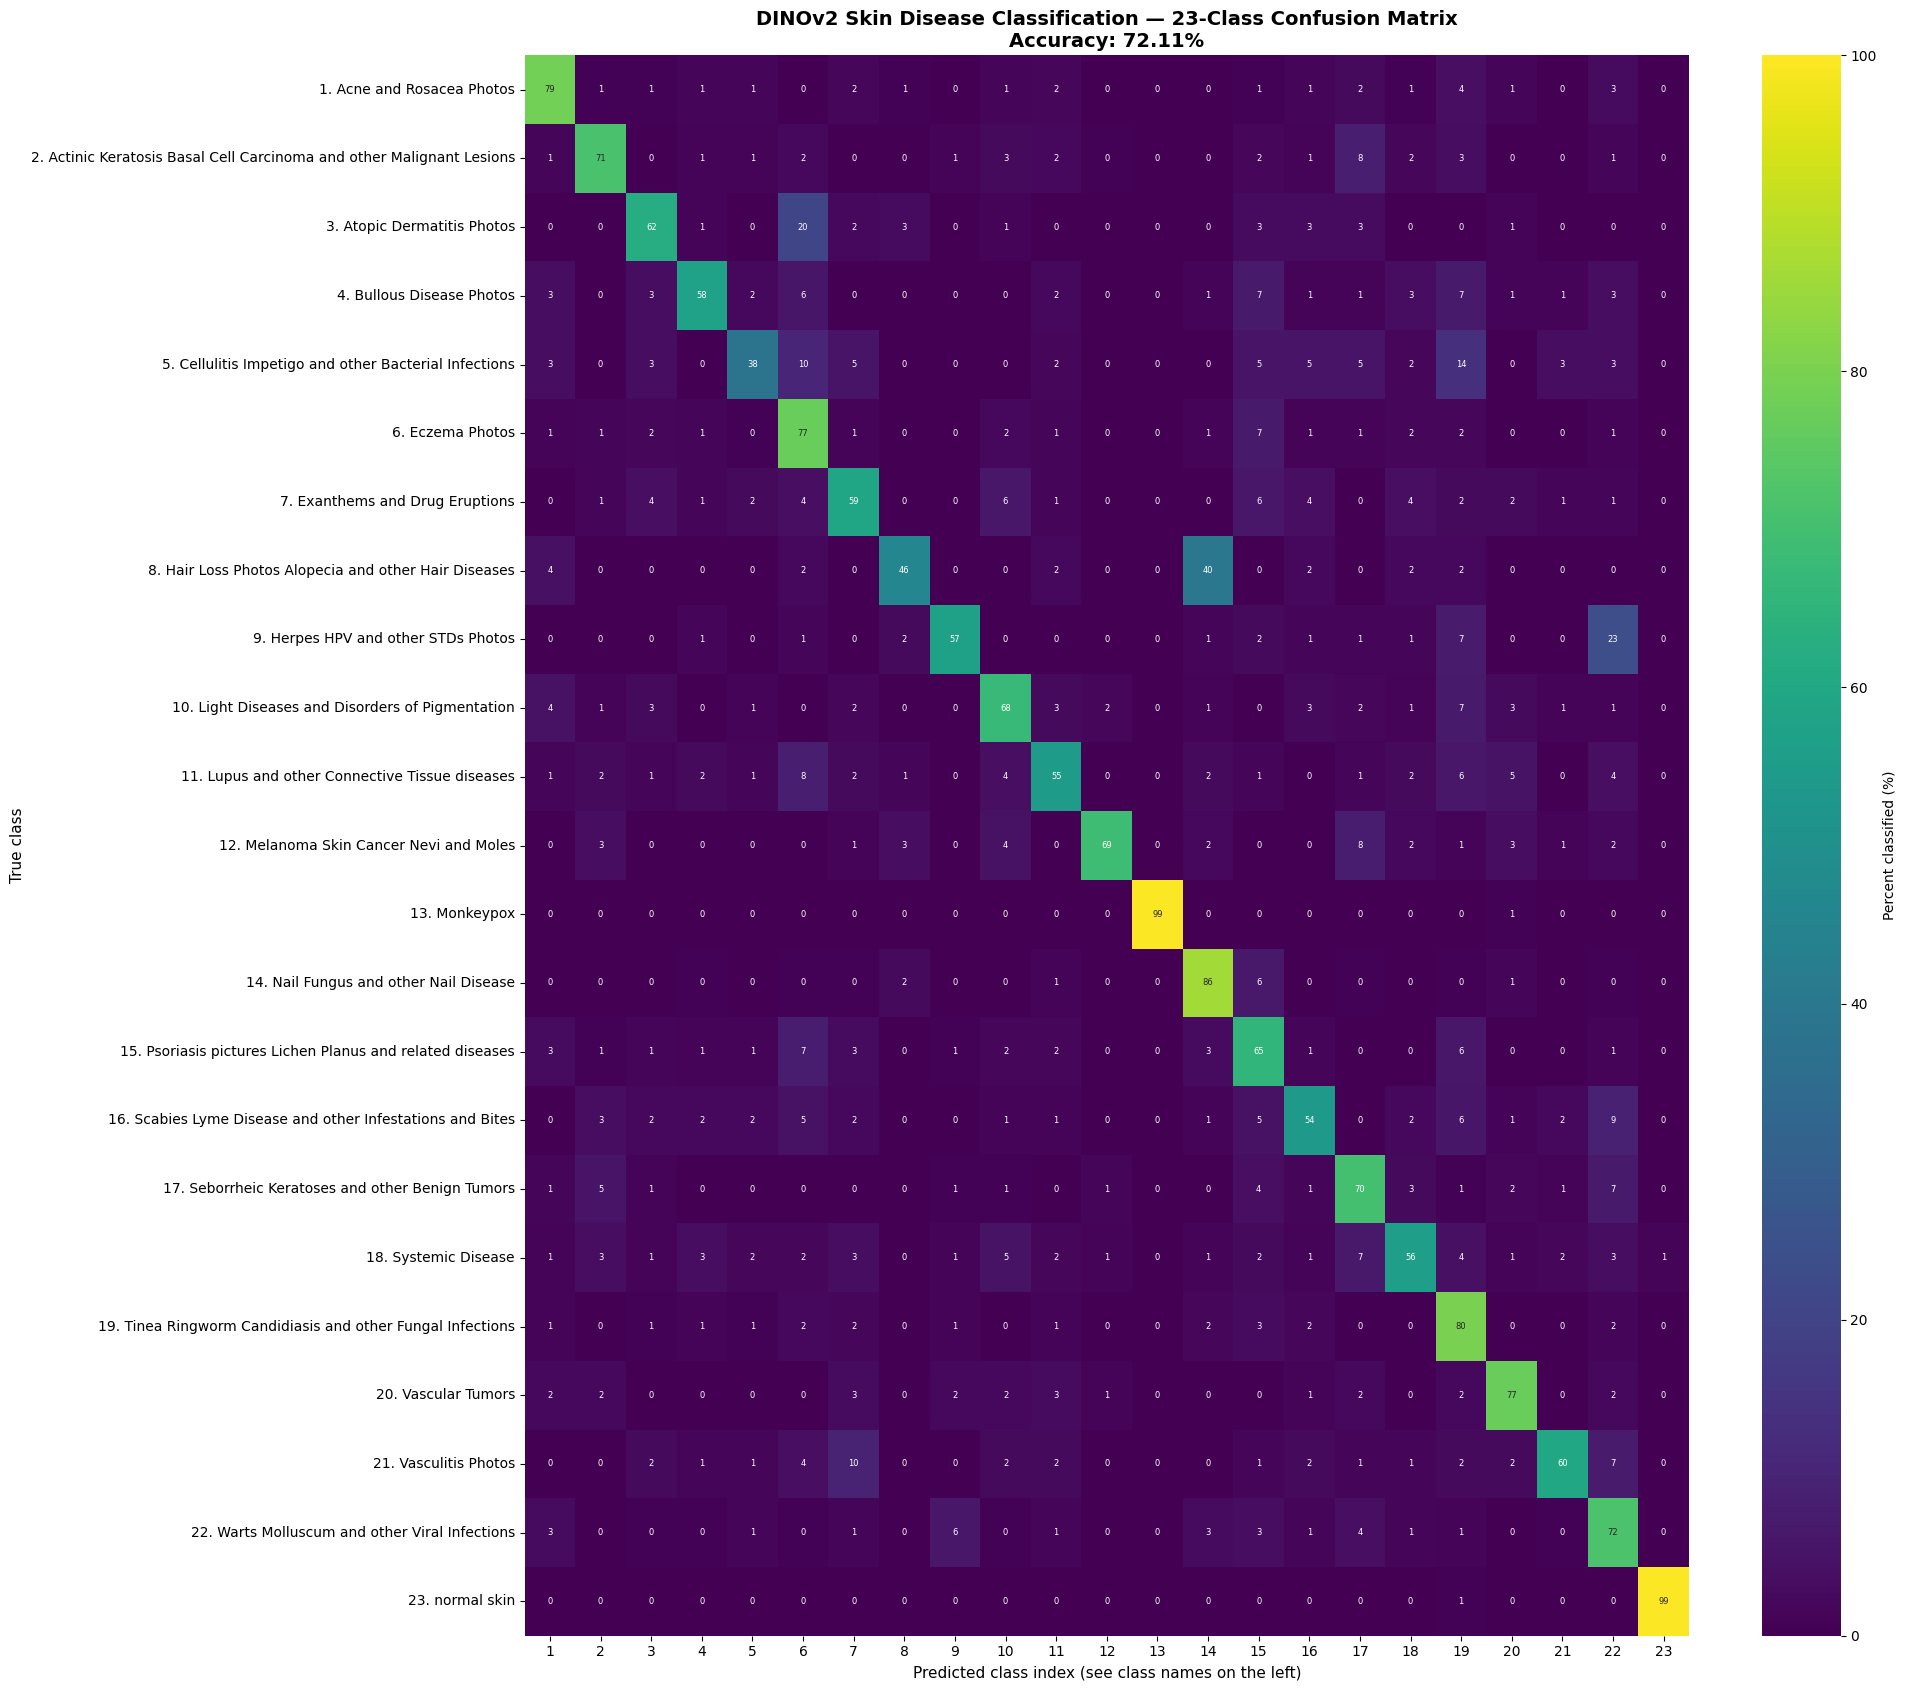


Classification report:
                                                                    precision    recall  f1-score   support

                                           Acne and Rosacea Photos     0.7586    0.7857    0.7719       168
Actinic Keratosis Basal Cell Carcinoma and other Malignant Lesions     0.8159    0.7130    0.7610       230
                                          Atopic Dermatitis Photos     0.6559    0.6224    0.6387        98
                                            Bullous Disease Photos     0.6582    0.5778    0.6154        90
                Cellulitis Impetigo and other Bacterial Infections     0.4681    0.3793    0.4190        58
                                                     Eczema Photos     0.6871    0.7733    0.7276       247
                                      Exanthems and Drug Eruptions     0.4948    0.5926    0.5393        81
                 Hair Loss Photos Alopecia and other Hair Diseases     0.5641    0.4583    0.5057        48
   

trainer_state.json:   0%|          | 0.00/9.65k [00:00<?, ?B/s]

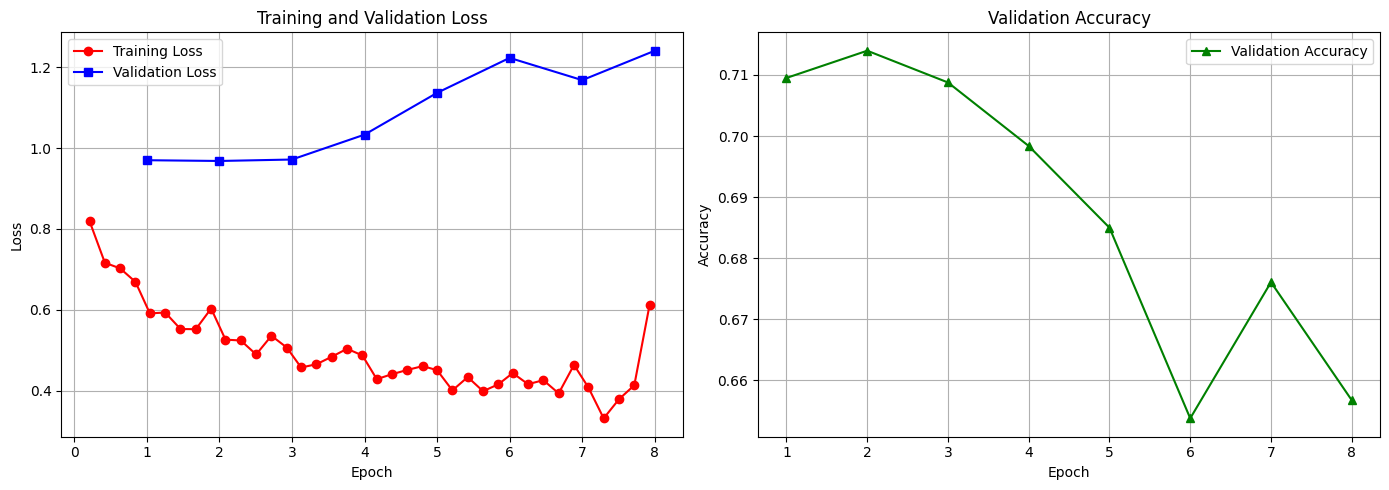

In [3]:
import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import AutoImageProcessor, AutoModelForImageClassification
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from huggingface_hub import hf_hub_download

# --------------------------------------------------
# 1. SETUP MODEL AND DATA PATHS
# --------------------------------------------------
MODEL_ID = "shindevaishnavi304/dinov2-finetuned-skin-disease"
OUTPUT_DIR = "/content/vit_confusion_matrix"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Dynamically search for the correct 'test' directory inside the downloaded path
# (Sometimes kagglehub has nested subdirectories)
possible_dataset_paths = [dataset_path, path] if 'dataset_path' in globals() else [path]
target_test_dir = None

for p in possible_dataset_paths:
    if not os.path.exists(p):
        continue
    for root, dirs, files_list in os.walk(p):
        if "test" in dirs:
            candidate = os.path.join(root, "test")
            # Confirm it has folders inside it (not empty)
            if any(os.path.isdir(os.path.join(candidate, d)) for d in os.listdir(candidate)):
                target_test_dir = candidate
                break
    if target_test_dir:
        break

if not target_test_dir:
    # Fallback to standard check
    target_test_dir = os.path.join(path, "test")

TEST_DIR = target_test_dir
print("Resolved Test directory path:", TEST_DIR)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

processor = AutoImageProcessor.from_pretrained(MODEL_ID)
model = AutoModelForImageClassification.from_pretrained(MODEL_ID)
model.to(device)
model.eval()

# --------------------------------------------------
# 2. LOAD TEST DATASET AND ALIGN LABELS
# --------------------------------------------------
test_ds = load_dataset(
    "imagefolder",
    data_dir=TEST_DIR,
    split="train"
)

dataset_names = test_ds.features["label"].names
id2label = model.config.id2label
model_names = [
    id2label.get(i, id2label.get(str(i)))
    for i in range(model.config.num_labels)
]

print("Test dataset classes:", len(dataset_names))
print("Model classes:", len(model_names))

# Align indices
class_names = model_names
dataset_to_model_idx = []
for name in dataset_names:
    if name in class_names:
        dataset_to_model_idx.append(class_names.index(name))
    else:
        matched = [i for i, m_name in enumerate(class_names) if m_name.lower().replace(" ", "") == name.lower().replace(" ", "")]
        if matched:
            dataset_to_model_idx.append(matched[0])
        else:
            raise ValueError(f"Could not map dataset class '{name}' to model classes.")

# --------------------------------------------------
# 3. RUN MODEL INFERENCE
# --------------------------------------------------
batch_size = 16
y_true = []
y_pred = []

for start in range(0, len(test_ds), batch_size):
    batch = test_ds[start:min(start + batch_size, len(test_ds))]
    images = [image.convert("RGB") for image in batch["image"]]
    true_ids = batch["label"]

    inputs = processor(images=images, return_tensors="pt")
    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        logits = model(**inputs).logits

    pred_ids = logits.argmax(dim=1).cpu().tolist()

    for t_id, p_id in zip(true_ids, pred_ids):
        y_true.append(dataset_to_model_idx[t_id])
        y_pred.append(p_id)

# --------------------------------------------------
# 4. MEASURE ACCURACY AND GENERATE PLOTS
# --------------------------------------------------
cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))
test_accuracy = accuracy_score(y_true, y_pred)

print(f"\nNumber of test images: {len(y_true)}")
print(f"Measured test accuracy: {test_accuracy:.4%}")

pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(f"{OUTPUT_DIR}/confusion_matrix_counts.csv")

row_sums = cm.sum(axis=1, keepdims=True)
cm_percent = np.divide(cm * 100.0, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0)

fig, ax = plt.subplots(figsize=(20, 17))
sns.heatmap(
    cm_percent,
    cmap="viridis",
    vmin=0,
    vmax=100,
    annot=True,
    fmt=".0f",
    annot_kws={"size": 6},
    xticklabels=[str(i + 1) for i in range(len(class_names))],
    yticklabels=[f"{i + 1}. {name}" for i, name in enumerate(class_names)],
    cbar_kws={"label": "Percent classified (%)"},
    ax=ax
)

ax.set_xlabel("Predicted class index (see class names on the left)", fontsize=11)
ax.set_ylabel("True class", fontsize=11)
ax.set_title(f"DINOv2 Skin Disease Classification — 23-Class Confusion Matrix\nAccuracy: {test_accuracy:.2%}", fontsize=14, fontweight="bold")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/ViT_23_class_confusion_matrix.png", dpi=400, bbox_inches="tight")
plt.show()

print("\nClassification report:")
print(classification_report(y_true, y_pred, labels=list(range(len(class_names))), target_names=class_names, digits=4, zero_division=0))

# --------------------------------------------------
# 5. RETRIEVE AND PLOT LOSS AND ACCURACY CURVES
# --------------------------------------------------
try:
    print("\nRetrieving training logs from Hugging Face hub...")
    trainer_state_path = hf_hub_download(repo_id=MODEL_ID, filename="trainer_state.json")
    with open(trainer_state_path, "r") as f:
        state = json.load(f)

    epochs = []
    loss = []
    eval_epochs = []
    eval_loss = []
    eval_accuracy = []

    for log in state.get("log_history", []):
        if "loss" in log and "epoch" in log:
            epochs.append(log["epoch"])
            loss.append(log["loss"])
        if "eval_loss" in log and "epoch" in log:
            eval_epochs.append(log["epoch"])
            eval_loss.append(log["eval_loss"])
            if "eval_accuracy" in log:
                eval_accuracy.append(log["eval_accuracy"])
            elif "eval_acc" in log:
                eval_accuracy.append(log["eval_acc"])

    if epochs or eval_epochs:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
        if loss:
            ax1.plot(epochs, loss, label="Training Loss", color="red", marker="o")
        if eval_loss:
            ax1.plot(eval_epochs, eval_loss, label="Validation Loss", color="blue", marker="s")
        ax1.set_title("Training and Validation Loss")
        ax1.set_xlabel("Epoch")
        ax1.set_ylabel("Loss")
        ax1.legend()
        ax1.grid(True)

        if eval_accuracy:
            ax2.plot(eval_epochs, eval_accuracy, label="Validation Accuracy", color="green", marker="^")
            ax2.set_title("Validation Accuracy")
            ax2.set_xlabel("Epoch")
            ax2.set_ylabel("Accuracy")
            ax2.legend()
            ax2.grid(True)

        plt.tight_layout()
        fig.savefig(f"{OUTPUT_DIR}/training_curves.png", dpi=300)
        plt.show()
    else:
        print("No history metrics found in trainer_state.json.")
except Exception as e:
    print("Could not retrieve or parse training history from Hugging Face Hub:", e)
